## STEP 1 - DATA COLLECTION & PREPARATION - Ingestion of Dataset from CELL2CELL

#### cell2cell_data_preparation.py

In [7]:
from __future__ import annotations

import argparse
import json
from pathlib import Path

import numpy as np
import pandas as pd

TARGET = "Churn"
ID_COLUMN = "CustomerID"
POTENTIAL_LEAKAGE_COLUMNS = ["RetentionCalls","RetentionOffersAccepted","MadeCallToRetentionTeam",]
TARGET_MAP = {"yes": 1, "no": 0, "1": 1, "0": 0}




def main() -> None:
    parser = argparse.ArgumentParser(description="Validate and normalize Cell2Cell source data.")
    parser.add_argument("--input", default="cell2celltrain.csv", help="Path to labelled Cell2Cell CSV.")
    parser.add_argument("--output-dir", default="outputs/data_prep", help="Directory for output artifacts.")
    args, _ = parser.parse_known_args()

    input_path = Path("cell2celltrain.csv")
    output_dir = Path("outputs/data_prep")
    output_dir.mkdir(parents=True, exist_ok=True)

    if not input_path.exists():
        raise FileNotFoundError(f"Input file not found: {input_path.resolve()}")

    raw = pd.read_csv(input_path, low_memory=False)
    if raw.empty:
        raise ValueError("Input dataset is empty.")

    initial_rows, initial_columns = raw.shape
    initial_duplicate_rows = int(raw.duplicated().sum())

    ###### Normalize column names and string values conservatively. ######
    df = raw.copy()
    df.columns = [str(c).strip() for c in df.columns]
    if df.columns.duplicated().any():
        duplicates = df.columns[df.columns.duplicated()].tolist()
        raise ValueError(f"Duplicate column names after trimming: {duplicates}")

    text_columns = df.select_dtypes(include=["object", "string"]).columns
    for column in text_columns:
        df[column] = df[column].map(lambda x: x.strip() if isinstance(x, str) else x)
        df[column] = df[column].replace("", np.nan)

    required = {TARGET, ID_COLUMN}
    missing_required = sorted(required - set(df.columns))
    if missing_required:
        raise ValueError(f"Missing required columns: {missing_required}")



    #### Remove exact duplicates, but do not deduplicate by ID automatically. ####3
    df = df.drop_duplicates().copy()
    duplicate_ids = int(df[ID_COLUMN].duplicated().sum())



    #### Normalize the target and reject unknown labels rather than guessing. #####
    normalized_target = df[TARGET].astype("string").str.strip().str.lower().map(TARGET_MAP)
    if normalized_target.isna().any():
        unexpected = sorted(
            df.loc[normalized_target.isna(), TARGET].astype("string").dropna().unique().tolist()
        )
        raise ValueError(f"Unexpected or missing target labels found: {unexpected}")
    df[TARGET] = normalized_target.astype("int64")

    if df[TARGET].nunique() != 2:
        raise ValueError("Target must contain both classes after normalization.")

    missing_by_column = df.isna().sum().sort_values(ascending=False)
    missing_by_column = missing_by_column[missing_by_column > 0]
    missing_total = int(df.isna().sum().sum())

    churn_counts = df[TARGET].value_counts().sort_index()
    churn_distribution = {
        "No (0)": int(churn_counts.get(0, 0)),
        "Yes (1)": int(churn_counts.get(1, 0)),
    }
    churn_rate = float(df[TARGET].mean())

    ##### Save normalized staging data. Missing predictors remain missing intentionally. #####
    cleaned_path = output_dir / "cell2cell_normalized_staging.csv"
    df.to_csv(cleaned_path, index=False)

    missing_path = output_dir / "missing_values_by_column.csv"
    missing_by_column.rename_axis("column").reset_index(name="missing_count").to_csv(
        missing_path, index=False
    )

    excluded_present = [c for c in [ID_COLUMN, *POTENTIAL_LEAKAGE_COLUMNS] if c in df.columns]
    summary = {
        "input_file": str(input_path.resolve()),
        "rows_before_duplicate_removal": int(initial_rows),
        "columns_before_normalization": int(initial_columns),
        "exact_duplicate_rows_found": initial_duplicate_rows,
        "exact_duplicate_rows_removed": initial_duplicate_rows,
        "rows_after_duplicate_removal": int(len(df)),
        "duplicate_customer_ids_after_exact_deduplication": duplicate_ids,
        "total_missing_cells_after_normalization": missing_total,
        "columns_with_missing_values": int(len(missing_by_column)),
        "target": TARGET,
        "target_mapping": {"No": 0, "Yes": 1},
        "target_distribution": churn_distribution,
        "churn_rate": churn_rate,
        "identifier_and_potential_leakage_columns_to_exclude_from_primary_features": excluded_present,
        "missing_value_policy": (
            "Predictor imputation must occur after splitting and be fitted on training data only. "
            "This script intentionally does not impute missing values."
        ),
        "outlier_policy": (
            "No automatic outlier deletion or capping is performed. Inspect ranges and data dictionary; "
            "correct or exclude only values shown to be invalid by documented rules."
        ),
        "normalized_staging_file": str(cleaned_path),
        "missing_values_file": str(missing_path),
    }
    summary_path = output_dir / "data_quality_summary.json"
    summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

    print("\n==================================")
    print("==================================")
    print("CELL2CELL DATA PREPARATION SUMMARY")
    print("===================================")
    print(f"Input: {input_path.resolve()}")
    print(f"Rows before duplicate removal: {initial_rows:,}")
    print(f"Exact duplicate rows removed: {initial_duplicate_rows:,}")
    print(f"Rows after duplicate removal: {len(df):,}")
    print(f"Duplicate CustomerIDs remaining: {duplicate_ids:,}")
    print(f"Missing cells after normalization: {missing_total:,}")
    print(f"Columns with missing values: {len(missing_by_column):,}")
    print(f"Churn distribution: {churn_distribution}")
    print(f"Normalized staging CSV: {cleaned_path}")
    print(f"Missing-values CSV: {missing_path}")
    print(f"Quality summary JSON: {summary_path}")
    print("\nNote: imputation, scaling, and encoding remain in the model pipeline to avoid leakage.")


if __name__ == "__main__":
    main()

CELL2CELL DATA PREPARATION SUMMARY
Input: C:\Users\Kayode Ogunyemi\PycharmProjects\Ann_FinalProject\cell2celltrain.csv
Rows before duplicate removal: 51,047
Exact duplicate rows removed: 0
Rows after duplicate removal: 51,047
Duplicate CustomerIDs remaining: 0
Missing cells after normalization: 3,515
Columns with missing values: 14
Churn distribution: {'No (0)': 36336, 'Yes (1)': 14711}
Normalized staging CSV: outputs\data_prep\cell2cell_normalized_staging.csv
Missing-values CSV: outputs\data_prep\missing_values_by_column.csv
Quality summary JSON: outputs\data_prep\data_quality_summary.json

Note: imputation, scaling, and encoding remain in the model pipeline to avoid leakage.


INTERPRETATION - The preparation process generated a normalized staging dataset, a missing-value report, and a JSON data-quality summary. The customer identifier and potential leakage variables were designated for exclusion from the primary model features. Imputation, feature scaling, and categorical encoding were deferred to the model pipeline, where preprocessing parameters would be learned from the training data and applied to the validation and test sets

## STEP 2 - MODEL EVALUATION & BASELINES - Establishing the ANN Baselines using the labelled Cell2Cell training file.

#### cell2cell_ann_baseline.py


DATA QUALITY SUMMARY
--------------------
Input file: C:\Users\Kayode Ogunyemi\PycharmProjects\Ann_FinalProject\cell2celltrain.csv
Rows before duplicate removal: 51,047
Exact duplicate rows removed: 0
Rows available for modelling: 51,047
Original columns: 58
Total missing cells before preprocessing: 3,515
Missing values by column:
AgeHH2                   909
AgeHH1                   909
PercChangeRevenues       367
PercChangeMinutes        367
MonthlyRevenue           156
MonthlyMinutes           156
RoamingCalls             156
OverageMinutes           156
DirectorAssistedCalls    156
TotalRecurringCharge     156
ServiceArea               24
Handsets                   1
CurrentEquipmentDays       1
HandsetModels              1
Churn distribution:
Churn
No (0)     36336
Yes (1)    14711
Excluded identifier columns: ['CustomerID']
Excluded potential leakage columns: ['RetentionCalls', 'RetentionOffersAccepted', 'MadeCallToRetentionTeam']
Preprocessing note: predictor imputers, scaling

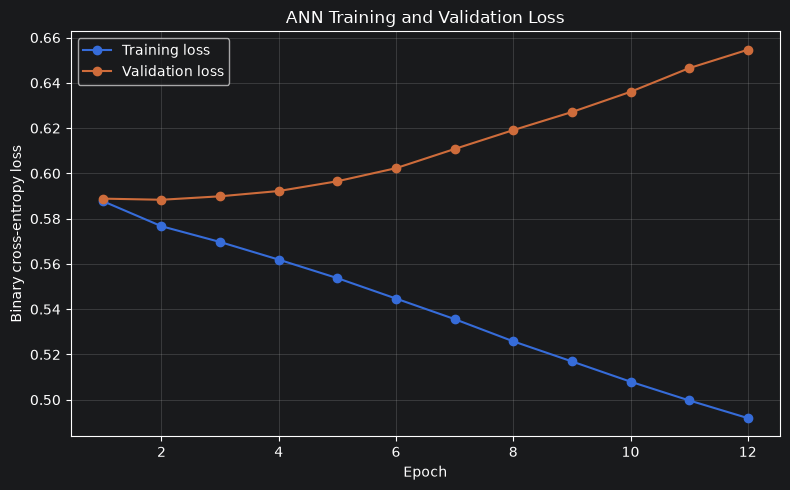

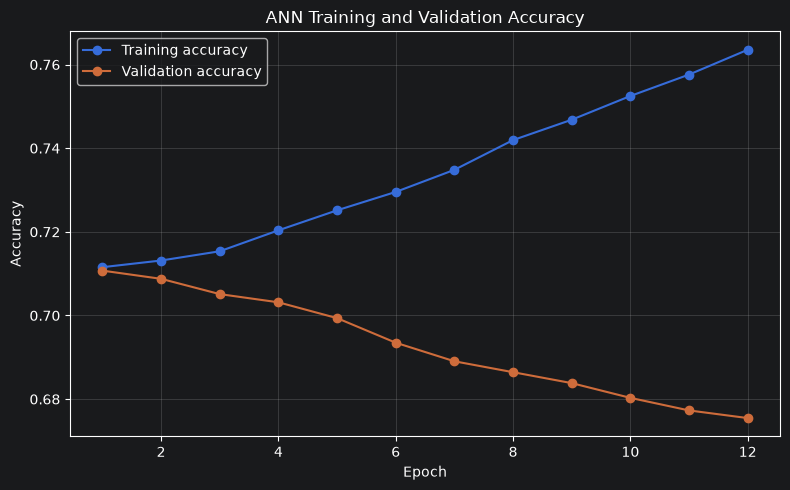

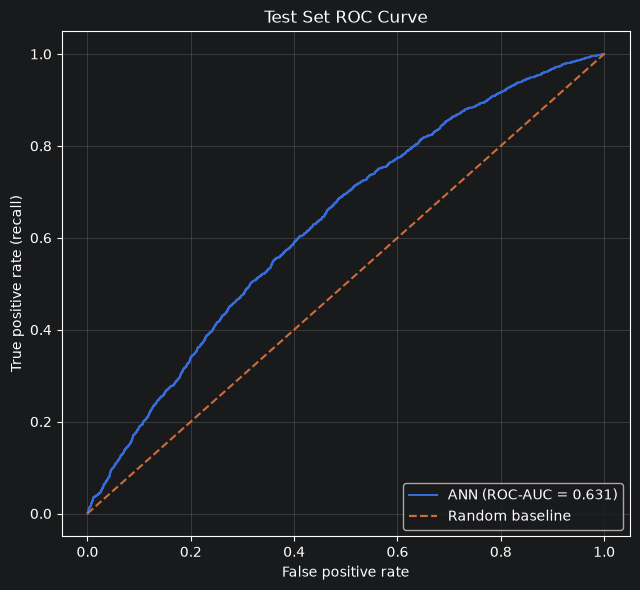

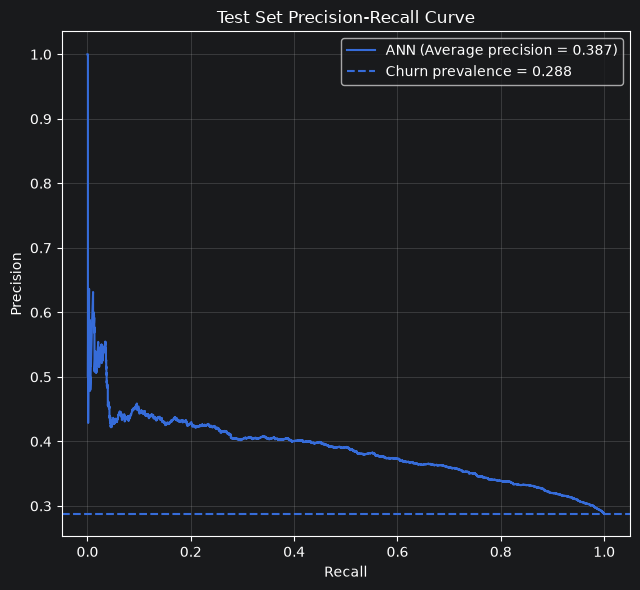

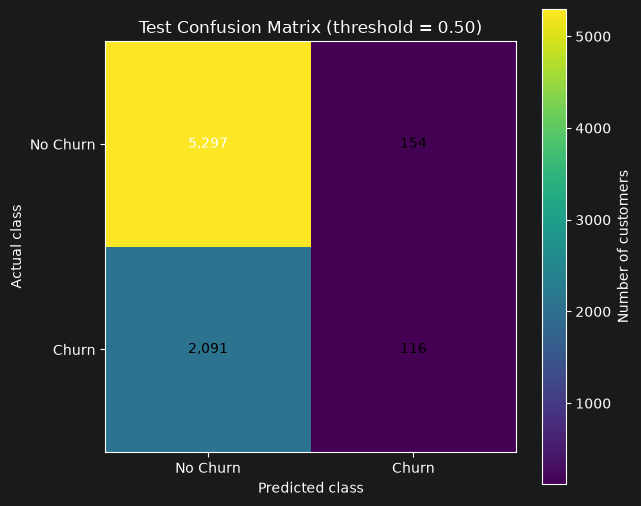

Plots saved to: C:\Users\Kayode Ogunyemi\PycharmProjects\Ann_FinalProject\outputs\cell2cell_baseline\plots

BASELINE TEST RESULTS
---------------------
accuracy: 0.7068
precision: 0.4296
recall: 0.0526
f1_score: 0.0937
roc_auc: 0.6314
average_precision: 0.3872
classification_threshold: 0.5000

TEST CLASSIFICATION REPORT
--------------------------
              precision    recall  f1-score   support

    No Churn       0.72      0.97      0.83      5451
       Churn       0.43      0.05      0.09      2207

    accuracy                           0.71      7658
   macro avg       0.57      0.51      0.46      7658
weighted avg       0.63      0.71      0.61      7658


TEST CONFUSION MATRIX (rows=actual, columns=predicted)
[[5297  154]
 [2091  116]]

Artifacts saved to: C:\Users\Kayode Ogunyemi\PycharmProjects\Ann_FinalProject\outputs\cell2cell_baseline
Do not report results from the previous dataset as Cell2Cell results.


In [13]:
from __future__ import annotations

import argparse
import json
import random
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
TEST_SIZE = 0.15
VALIDATION_SIZE = 0.15
BATCH_SIZE = 32
MAX_EPOCHS = 100
EARLY_STOPPING_PATIENCE = 10
LEARNING_RATE = 0.001
CLASSIFICATION_THRESHOLD = 0.50

ID_COLUMNS = ["CustomerID"]
POTENTIAL_LEAKAGE_COLUMNS = [
    "RetentionCalls",
    "RetentionOffersAccepted",
    "MadeCallToRetentionTeam",
]


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(
        description="Train and evaluate a baseline ANN using Cell2Cell churn data."
    )
    parser.add_argument(
        "--data",
        default="cell2celltrain.csv",
        help="Path to labelled Cell2Cell training CSV (default: cell2celltrain.csv).",
    )
    parser.add_argument(
        "--output-dir",
        default="outputs/cell2cell_baseline",
        help="Directory for model, metrics, and evaluation artifacts.",
    )
    return parser.parse_known_args()[0]


def set_seeds(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


def load_and_validate_data(data_path: Path) -> tuple[pd.DataFrame, dict]:
    if not data_path.exists():
        raise FileNotFoundError(
            f"Dataset not found: {data_path.resolve()}\n"
            "Place cell2celltrain.csv in the project directory or pass --data with its path."
        )

    dataset = pd.read_csv(data_path, low_memory=False)
    dataset.columns = dataset.columns.str.strip()

    required_columns = {"Churn", "CustomerID"}
    missing_columns = required_columns - set(dataset.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {sorted(missing_columns)}. "
            f"Available columns: {dataset.columns.tolist()}"
        )
    if dataset.empty:
        raise ValueError("The dataset contains no records.")

    initial_rows = len(dataset)
    duplicate_count = int(dataset.duplicated().sum())
    if duplicate_count:
        dataset = dataset.drop_duplicates().copy()

    # Trim string values and turn blank strings into missing values.
    object_columns = dataset.select_dtypes(include=["object", "string"]).columns
    for column in object_columns:
        dataset[column] = dataset[column].map(
            lambda value: value.strip() if isinstance(value, str) else value
        )
        dataset[column] = dataset[column].replace("", np.nan)

    # Normalize target labels.
    target = dataset["Churn"].astype("string").str.strip().str.lower()
    target_map = {"yes": 1, "no": 0, "1": 1, "0": 0}
    normalized_target = target.map(target_map)
    if normalized_target.isna().any():
        unexpected = sorted(target[normalized_target.isna()].dropna().unique().tolist())
        raise ValueError(
            "Churn must contain Yes/No or 1/0 values. "
            f"Unexpected target values: {unexpected}"
        )
    dataset["Churn"] = normalized_target.astype("int64")

    if dataset["Churn"].nunique() != 2:
        raise ValueError("Churn target must contain both classes (0 and 1).")

    missing_by_column = dataset.isna().sum()
    missing_by_column = missing_by_column[missing_by_column > 0].sort_values(ascending=False)

    # Report the excluded columns that are present in this version of the file.
    present_id_columns = [c for c in ID_COLUMNS if c in dataset.columns]
    present_leakage_columns = [c for c in POTENTIAL_LEAKAGE_COLUMNS if c in dataset.columns]
    excluded_columns = present_id_columns + present_leakage_columns

    print("\nDATA QUALITY SUMMARY")
    print("--------------------")
    print(f"Input file: {data_path.resolve()}")
    print(f"Rows before duplicate removal: {initial_rows:,}")
    print(f"Exact duplicate rows removed: {duplicate_count:,}")
    print(f"Rows available for modelling: {len(dataset):,}")
    print(f"Original columns: {dataset.shape[1]:,}")
    print(f"Total missing cells before preprocessing: {int(dataset.isna().sum().sum()):,}")
    print("Missing values by column:")
    if missing_by_column.empty:
        print("  None")
    else:
        print(missing_by_column.to_string())
    print(
        "Churn distribution:\n"
        + dataset["Churn"].value_counts().sort_index()
        .rename(index={0: "No (0)", 1: "Yes (1)"}).to_string()
    )
    print(f"Excluded identifier columns: {present_id_columns or 'None'}")
    print(f"Excluded potential leakage columns: {present_leakage_columns or 'None'}")
    print(
        "Preprocessing note: predictor imputers, scaling, and encoding are fitted "
        "on the training split only."
    )

    config = {
        "input_file": str(data_path.resolve()),
        "input_rows": int(initial_rows),
        "rows_after_duplicate_removal": int(len(dataset)),
        "duplicate_rows_removed": int(duplicate_count),
        "columns_in_input": int(dataset.shape[1]),
        "total_missing_cells_before_preprocessing": int(dataset.isna().sum().sum()),
        "missing_values_by_column": {str(k): int(v) for k, v in missing_by_column.items()},
        "churn_counts": {str(k): int(v) for k, v in dataset["Churn"].value_counts().items()},
        "excluded_identifier_columns": present_id_columns,
        "excluded_potential_leakage_columns": present_leakage_columns,
    }
    return dataset, config


def make_preprocessor(X_train: pd.DataFrame) -> ColumnTransformer:
    numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
    categorical_features = [col for col in X_train.columns if col not in numeric_features]

    numeric_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]
    )
    categorical_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numeric_features),
            ("categorical", categorical_pipeline, categorical_features),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


def build_baseline_ann(input_dim: int) -> tf.keras.Model:
    model = tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(input_dim,), name="customer_features"),
            tf.keras.layers.Dense(32, activation="relu", name="hidden_layer_1"),
            tf.keras.layers.Dense(16, activation="relu", name="hidden_layer_2"),
            tf.keras.layers.Dense(1, activation="sigmoid", name="churn_probability"),
        ],
        name="cell2cell_baseline_ann",
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
        ],
    )
    return model


def compute_metrics(y_true: np.ndarray, probabilities: np.ndarray) -> dict:
    predictions = (probabilities >= CLASSIFICATION_THRESHOLD).astype(int)
    return {
        "accuracy": float(accuracy_score(y_true, predictions)),
        "precision": float(precision_score(y_true, predictions, zero_division=0)),
        "recall": float(recall_score(y_true, predictions, zero_division=0)),
        "f1_score": float(f1_score(y_true, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, probabilities)),
        "average_precision": float(average_precision_score(y_true, probabilities)),
        "classification_threshold": CLASSIFICATION_THRESHOLD,
    }



def save_data_visualizations(dataset: pd.DataFrame, output_dir: Path) -> None:
    """Save descriptive charts for data quality and target distribution."""
    plot_dir = output_dir / "plots"
    plot_dir.mkdir(parents=True, exist_ok=True)

    # 1. Target class distribution
    churn_counts = dataset["Churn"].value_counts().reindex([0, 1], fill_value=0)
    fig, ax = plt.subplots(figsize=(7, 5))
    bars = ax.bar(["No Churn", "Churn"], churn_counts.values)
    ax.set_title("Cell2Cell Churn Class Distribution")
    ax.set_ylabel("Number of customers")
    ax.bar_label(bars, fmt="%d")
    fig.tight_layout()
    fig.savefig(plot_dir / "01_churn_distribution.png", dpi=200, bbox_inches="tight")
    plt.close(fig)

    # 2. Missing values by column (top 15)
    missing = dataset.isna().sum().sort_values(ascending=False)
    missing = missing[missing > 0].head(15).sort_values()
    if not missing.empty:
        fig, ax = plt.subplots(figsize=(9, max(5, 0.35 * len(missing))))
        bars = ax.barh(missing.index.astype(str), missing.values)
        ax.set_title("Columns with the Most Missing Values")
        ax.set_xlabel("Missing cells")
        ax.bar_label(bars, fmt="%d", padding=3)
        fig.tight_layout()
        fig.savefig(plot_dir / "02_missing_values_by_column.png", dpi=200, bbox_inches="tight")
        plt.close(fig)


def save_model_visualizations(
    history: tf.keras.callbacks.History,
    y_true: np.ndarray,
    probabilities: np.ndarray,
    threshold: float,
    output_dir: Path,
) -> None:
    """Save training curves and test-set classification performance charts."""
    from sklearn.metrics import roc_curve, precision_recall_curve

    plot_dir = output_dir / "plots"
    plot_dir.mkdir(parents=True, exist_ok=True)
    history_data = history.history

    # 3. Training and validation loss
    if "loss" in history_data and "val_loss" in history_data:
        fig, ax = plt.subplots(figsize=(8, 5))
        epochs = range(1, len(history_data["loss"]) + 1)
        ax.plot(epochs, history_data["loss"], marker="o", label="Training loss")
        ax.plot(epochs, history_data["val_loss"], marker="o", label="Validation loss")
        ax.set_title("ANN Training and Validation Loss")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Binary cross-entropy loss")
        ax.legend()
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        fig.savefig(plot_dir / "03_training_validation_loss.png", dpi=200, bbox_inches="tight")
        plt.show(fig)
        plt.close(fig)

    # 4. Training and validation accuracy
    if "accuracy" in history_data and "val_accuracy" in history_data:
        fig, ax = plt.subplots(figsize=(8, 5))
        epochs = range(1, len(history_data["accuracy"]) + 1)
        ax.plot(epochs, history_data["accuracy"], marker="o", label="Training accuracy")
        ax.plot(epochs, history_data["val_accuracy"], marker="o", label="Validation accuracy")
        ax.set_title("ANN Training and Validation Accuracy")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Accuracy")
        ax.legend()
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        fig.savefig(plot_dir / "04_training_validation_accuracy.png", dpi=200, bbox_inches="tight")
        plt.show(fig)
        plt.close(fig)

    # 5. ROC curve
    fpr, tpr, _ = roc_curve(y_true, probabilities)
    roc_auc = roc_auc_score(y_true, probabilities)
    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.plot(fpr, tpr, label=f"ANN (ROC-AUC = {roc_auc:.3f})")
    ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
    ax.set_title("Test Set ROC Curve")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate (recall)")
    ax.legend(loc="lower right")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(plot_dir / "05_test_roc_curve.png", dpi=200, bbox_inches="tight")
    plt.show(fig)
    plt.close(fig)

    # 6. Precision-recall curve
    precision, recall, _ = precision_recall_curve(y_true, probabilities)
    average_precision = average_precision_score(y_true, probabilities)
    prevalence = float(np.mean(y_true))
    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.plot(recall, precision, label=f"ANN (Average precision = {average_precision:.3f})")
    ax.axhline(prevalence, linestyle="--", label=f"Churn prevalence = {prevalence:.3f}")
    ax.set_title("Test Set Precision-Recall Curve")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(loc="best")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(plot_dir / "06_test_precision_recall_curve.png", dpi=200, bbox_inches="tight")
    plt.show(fig)
    plt.close(fig)

    # 7. Confusion matrix
    predicted = (probabilities >= threshold).astype(int)
    matrix = confusion_matrix(y_true, predicted, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    image = ax.imshow(matrix, interpolation="nearest")
    ax.set_title(f"Test Confusion Matrix (threshold = {threshold:.2f})")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.set_xticks([0, 1], labels=["No Churn", "Churn"])
    ax.set_yticks([0, 1], labels=["No Churn", "Churn"])
    fig.colorbar(image, ax=ax, label="Number of customers")
    midpoint = matrix.max() / 2 if matrix.size else 0
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            ax.text(col, row, f"{matrix[row, col]:,}", ha="center", va="center",
                    color="white" if matrix[row, col] > midpoint else "black")
    fig.tight_layout()
    fig.savefig(plot_dir / "07_test_confusion_matrix.png", dpi=200, bbox_inches="tight")
    plt.show(fig)
    plt.close(fig)


    # 8. Predicted probability distribution by actual class
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(probabilities[np.asarray(y_true) == 0], bins=30, alpha=0.65, label="Actual No Churn")
    ax.hist(probabilities[np.asarray(y_true) == 1], bins=30, alpha=0.65, label="Actual Churn")
    ax.axvline(threshold, linestyle="--", label=f"Classification threshold = {threshold:.2f}")
    ax.set_title("Predicted Churn Probability by Actual Class")
    ax.set_xlabel("Predicted probability of churn")
    ax.set_ylabel("Number of customers")
    ax.legend()
    ax.grid(True, alpha=0.25)
    fig.tight_layout()
    fig.savefig(plot_dir / "08_predicted_probability_distribution.png", dpi=200, bbox_inches="tight")
    plt.close(fig)
    plt.show(fig)

    print(f"Plots saved to: {plot_dir.resolve()}")


def main() -> int:
    args = parse_args()
    data_path = Path(args.data).expanduser()
    output_dir = Path(args.output_dir).expanduser()
    output_dir.mkdir(parents=True, exist_ok=True)

    set_seeds()
    dataset, data_quality = load_and_validate_data(data_path)
    save_data_visualizations(dataset, output_dir)

    excluded = [
        column for column in ID_COLUMNS + POTENTIAL_LEAKAGE_COLUMNS
        if column in dataset.columns
    ]
    X = dataset.drop(columns=["Churn"] + excluded)
    y = dataset["Churn"].astype("int64")

    # Stratified 70% train / 30% temporary split.
    X_train, X_temp, y_train, y_temp = train_test_split(
        X,
        y,
        test_size=TEST_SIZE + VALIDATION_SIZE,
        random_state=SEED,
        stratify=y,
    )

    # Split temporary data equally into 15% validation and 15% test.
    relative_test_size = TEST_SIZE / (TEST_SIZE + VALIDATION_SIZE)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=relative_test_size,
        random_state=SEED,
        stratify=y_temp,
    )

    preprocessor = make_preprocessor(X_train)
    X_train_processed = preprocessor.fit_transform(X_train).astype("float32")
    X_val_processed = preprocessor.transform(X_val).astype("float32")
    X_test_processed = preprocessor.transform(X_test).astype("float32")

    print("\nEXPERIMENT DESIGN")
    print("-----------------")
    print(f"Train/validation/test rows: {len(X_train):,}/{len(X_val):,}/{len(X_test):,}")
    print(f"Predictor columns before encoding: {X_train.shape[1]:,}")
    print(f"Encoded feature count: {X_train_processed.shape[1]:,}")
    print(f"Architecture: input -> 32 -> 16 -> 1")
    print(f"Optimizer: Adam; learning rate: {LEARNING_RATE}")
    print(f"Batch size: {BATCH_SIZE}; maximum epochs: {MAX_EPOCHS}")
    print(f"Early stopping patience: {EARLY_STOPPING_PATIENCE}")
    print(f"Classification threshold: {CLASSIFICATION_THRESHOLD:.2f}")
    print("Test data is held back until final evaluation.")

    model = build_baseline_ann(X_train_processed.shape[1])
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1,
    )

    history = model.fit(
        X_train_processed,
        y_train.to_numpy(),
        validation_data=(X_val_processed, y_val.to_numpy()),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        verbose=2,
    )

    probabilities = model.predict(X_test_processed, verbose=0).ravel()
    metrics = compute_metrics(y_test.to_numpy(), probabilities)
    report = classification_report(
        y_test,
        (probabilities >= CLASSIFICATION_THRESHOLD).astype(int),
        target_names=["No Churn", "Churn"],
        output_dict=True,
        zero_division=0,
    )
    matrix = confusion_matrix(
        y_test,
        (probabilities >= CLASSIFICATION_THRESHOLD).astype(int),
        labels=[0, 1],
    )
    save_model_visualizations(
        history=history,
        y_true=y_test.to_numpy(),
        probabilities=probabilities,
        threshold=CLASSIFICATION_THRESHOLD,
        output_dir=output_dir,
    )

    # Persist all artifacts needed to reproduce and document the experiment.
    model.save(output_dir / "baseline_ann.keras")
    joblib.dump(preprocessor, output_dir / "preprocessor.joblib")
    pd.DataFrame(history.history).to_csv(output_dir / "training_history.csv", index=False)
    pd.DataFrame(
        matrix,
        index=["actual_no_churn", "actual_churn"],
        columns=["predicted_no_churn", "predicted_churn"],
    ).to_csv(output_dir / "confusion_matrix.csv")
    pd.DataFrame(
        {
            "actual_churn": y_test.to_numpy(),
            "churn_probability": probabilities,
            "predicted_churn": (probabilities >= CLASSIFICATION_THRESHOLD).astype(int),
        }
    ).to_csv(output_dir / "test_predictions.csv", index=False)

    with (output_dir / "baseline_metrics.json").open("w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=2)
    with (output_dir / "classification_report.json").open("w", encoding="utf-8") as f:
        json.dump(report, f, indent=2)
    with (output_dir / "data_quality_summary.json").open("w", encoding="utf-8") as f:
        json.dump(data_quality, f, indent=2)

    run_config = {
        **data_quality,
        "seed": SEED,
        "train_rows": int(len(X_train)),
        "validation_rows": int(len(X_val)),
        "test_rows": int(len(X_test)),
        "predictor_columns_before_encoding": int(X_train.shape[1]),
        "encoded_features": int(X_train_processed.shape[1]),
        "architecture": [32, 16, 1],
        "hidden_activation": "relu",
        "output_activation": "sigmoid",
        "optimizer": "Adam",
        "learning_rate": LEARNING_RATE,
        "loss": "binary_crossentropy",
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "epochs_trained": int(len(history.history.get("loss", []))),
        "classification_threshold": CLASSIFICATION_THRESHOLD,
        "metrics": metrics,
    }
    with (output_dir / "run_config.json").open("w", encoding="utf-8") as f:
        json.dump(run_config, f, indent=2)

    print("\nBASELINE TEST RESULTS")
    print("---------------------")
    for key, value in metrics.items():
        print(f"{key}: {value:.4f}" if isinstance(value, float) else f"{key}: {value}")
    print("\nTEST CLASSIFICATION REPORT")
    print("--------------------------")
    print(
        classification_report(
            y_test,
            (probabilities >= CLASSIFICATION_THRESHOLD).astype(int),
            target_names=["No Churn", "Churn"],
            zero_division=0,
        )
    )
    print("\nTEST CONFUSION MATRIX (rows=actual, columns=predicted)")
    print(matrix)
    print(f"\nArtifacts saved to: {output_dir.resolve()}")
    print("Do not report results from the previous dataset as Cell2Cell results.")
    return 0


if __name__ == "__main__":
    main()


**INTERPRETATION** - At the default threshold of 0.50, the model misses 2,091 of 2,207 churners, or approximately 94.74%. This is a major limitation for a business whose objective is to identify customers for retention campaigns. **These findings indicate that the baseline ANN has limited usefulness for identifying churners at the default threshold**. Subsequent experiments should investigate classification-threshold optimization and model improvements, using validation data for model selection and reserving the test set for final evaluation.

## STEP 3 - OPTIMIZATION EXPERIMENTS -

cell2cell_ann_threshold_analysis.py cell2cell_logistic_threshold_benchmark.py

In this step - I will be comparing the baseline and optimized model using the same test split, include the plots as figures with captions, and explain how the results relate to the business goal of identifying customers who may churn.

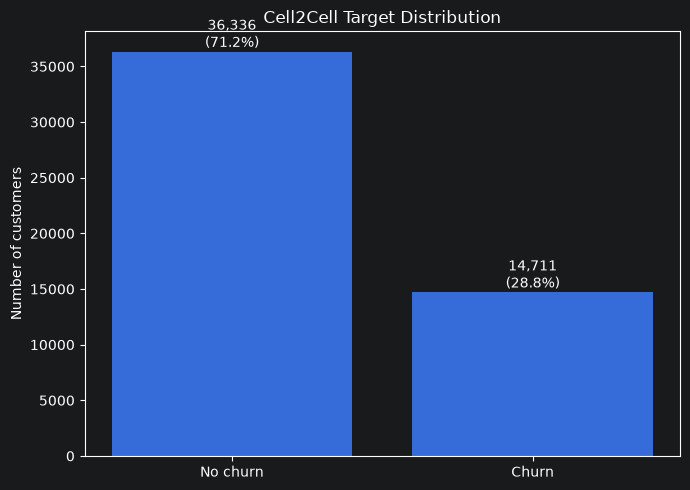

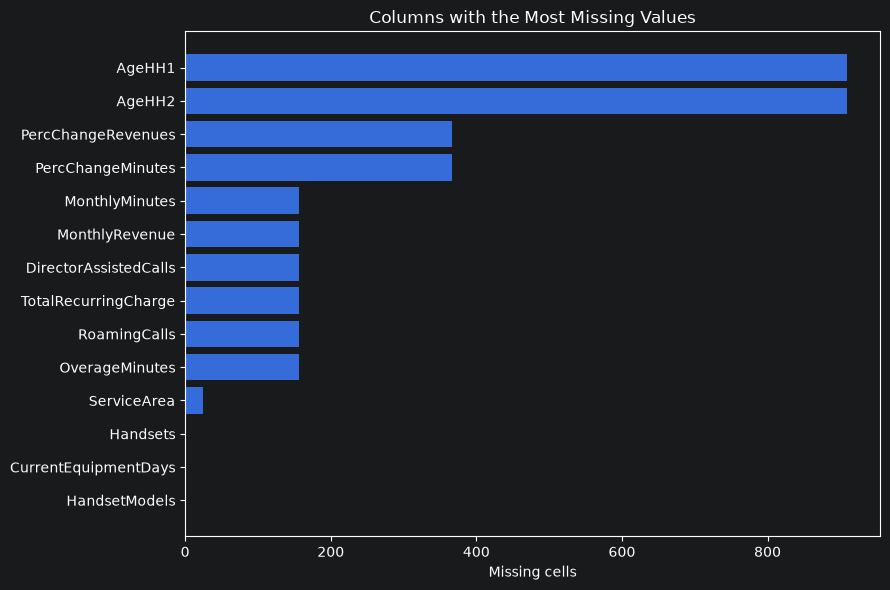

Epoch 1/100
1117/1117 - 4s - 3ms/step - accuracy: 0.7115 - loss: 0.5877 - pr_auc: 0.3643 - roc_auc: 0.6012 - val_accuracy: 0.7107 - val_loss: 0.5889 - val_pr_auc: 0.3641 - val_roc_auc: 0.6024
Epoch 2/100
1117/1117 - 2s - 2ms/step - accuracy: 0.7131 - loss: 0.5767 - pr_auc: 0.4012 - roc_auc: 0.6366 - val_accuracy: 0.7088 - val_loss: 0.5884 - val_pr_auc: 0.3694 - val_roc_auc: 0.6078
Epoch 3/100
1117/1117 - 2s - 2ms/step - accuracy: 0.7154 - loss: 0.5697 - pr_auc: 0.4218 - roc_auc: 0.6545 - val_accuracy: 0.7051 - val_loss: 0.5899 - val_pr_auc: 0.3703 - val_roc_auc: 0.6082
Epoch 4/100
1117/1117 - 2s - 2ms/step - accuracy: 0.7204 - loss: 0.5619 - pr_auc: 0.4451 - roc_auc: 0.6720 - val_accuracy: 0.7031 - val_loss: 0.5922 - val_pr_auc: 0.3721 - val_roc_auc: 0.6092
Epoch 5/100
1117/1117 - 11s - 10ms/step - accuracy: 0.7251 - loss: 0.5537 - pr_auc: 0.4675 - roc_auc: 0.6883 - val_accuracy: 0.6994 - val_loss: 0.5965 - val_pr_auc: 0.3720 - val_roc_auc: 0.6090
Epoch 6/100
1117/1117 - 12s - 11ms/ste

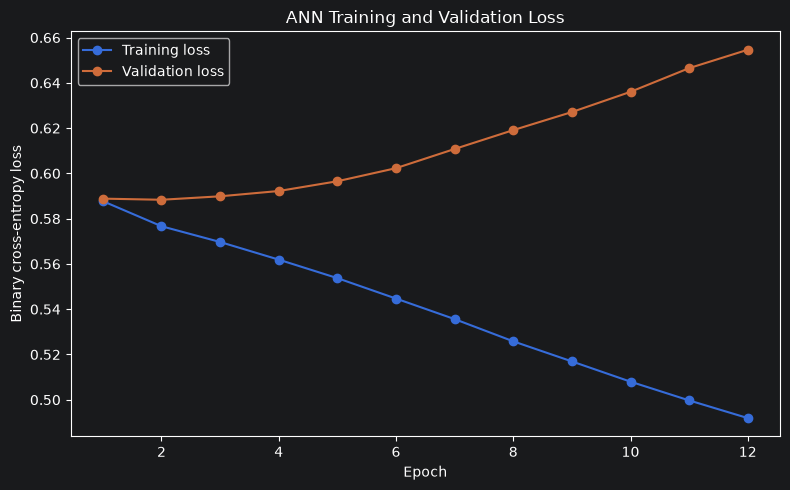

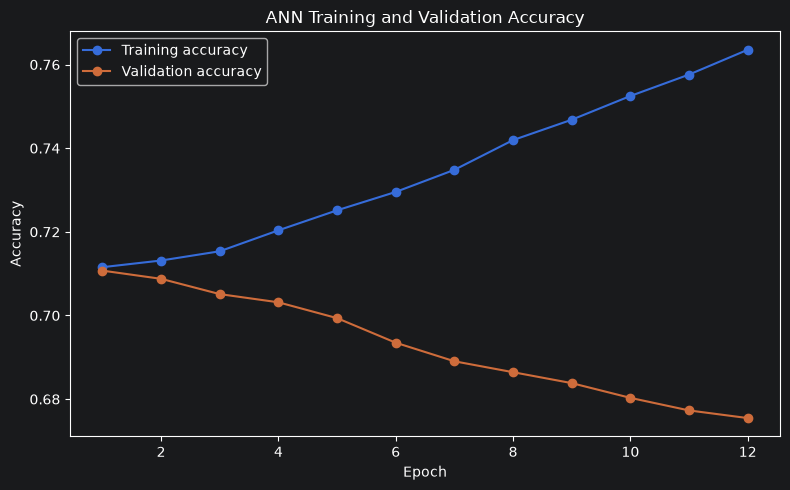

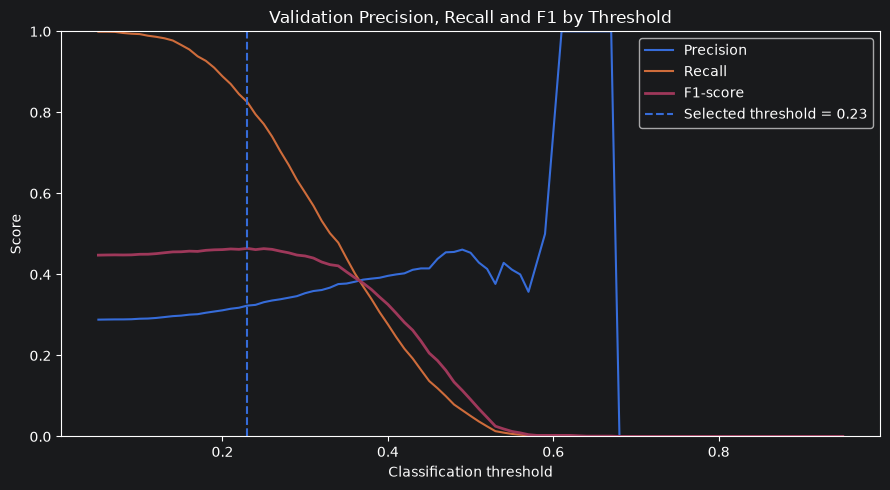

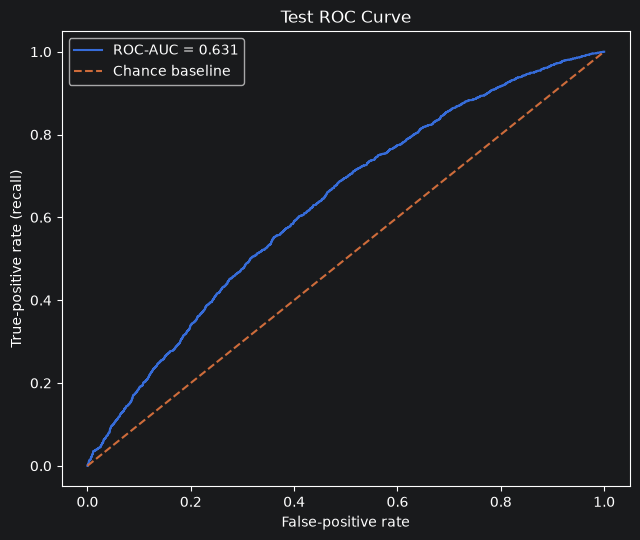

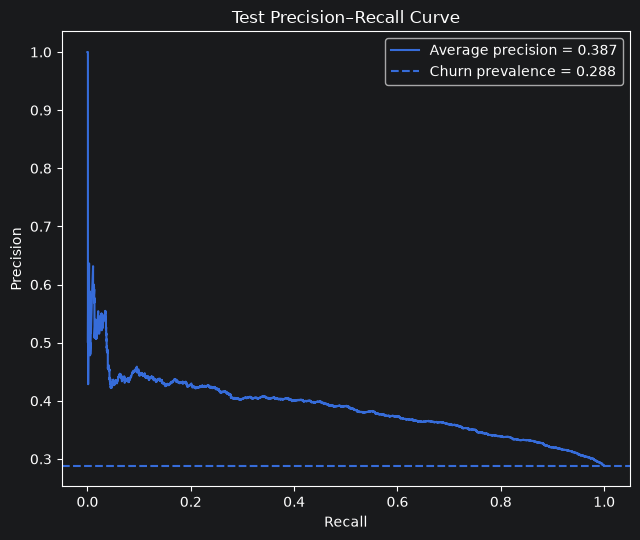

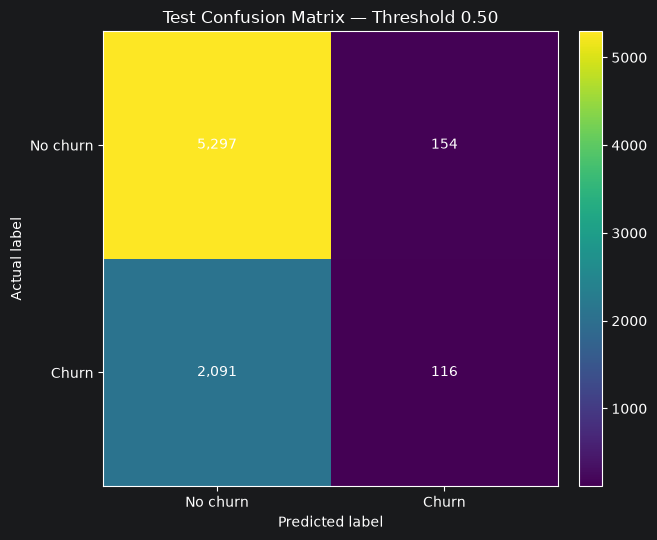

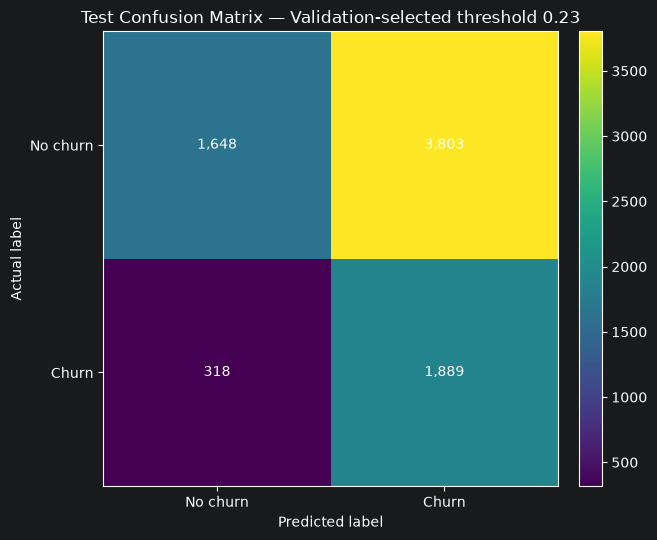

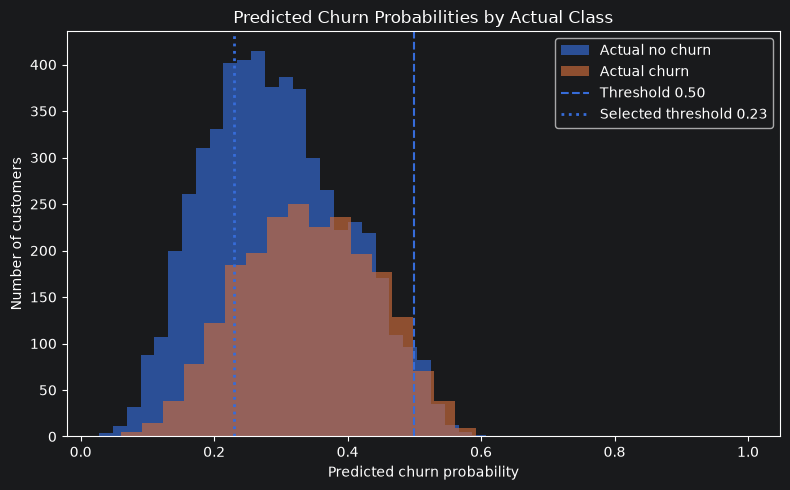


ANN VALIDATION-SELECTED THRESHOLD: 0.23
VALIDATION METRICS: {'threshold': 0.23, 'accuracy': 0.4509599059683949, 'precision': 0.32299237723807833, 'recall': 0.8255550521069325, 'f1_score': 0.464322120285423, 'roc_auc': 0.6077798747105748, 'average_precision': 0.36973826640151897}
TEST METRICS AT 0.50: {'threshold': 0.5, 'accuracy': 0.7068425176286237, 'precision': 0.42962962962962964, 'recall': 0.05256003624830086, 'f1_score': 0.09366168752523213, 'roc_auc': 0.6313502167890778, 'average_precision': 0.38721486247598436, 'confusion_matrix': [[5297, 154], [2091, 116]]}
TEST METRICS AT VALIDATION-SELECTED THRESHOLD: {'threshold': 0.23, 'accuracy': 0.46186993993209713, 'precision': 0.3318692902319044, 'recall': 0.8559130040779338, 'f1_score': 0.47828839093556147, 'roc_auc': 0.6313502167890778, 'average_precision': 0.38721486247598436, 'confusion_matrix': [[1648, 3803], [318, 1889]]}

Charts saved to: C:\Users\Kayode Ogunyemi\PycharmProjects\Ann_FinalProject\outputs\cell2cell_ann_threshold_a

In [17]:
from __future__ import annotations

import argparse
import json
import random
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
ID_COLUMNS = ["CustomerID"]
LEAKAGE_COLUMNS = [
    "RetentionCalls",
    "RetentionOffersAccepted",
    "MadeCallToRetentionTeam",
]


def metrics(y, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(y, predictions)),
        "precision": float(precision_score(y, predictions, zero_division=0)),
        "recall": float(recall_score(y, predictions, zero_division=0)),
        "f1_score": float(f1_score(y, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(y, probabilities)),
        "average_precision": float(average_precision_score(y, probabilities)),
        "confusion_matrix": confusion_matrix(y, predictions, labels=[0, 1]).tolist(),
    }


def save_plot(fig, plot_dir: Path, filename: str):
    fig.tight_layout()
    fig.savefig(plot_dir / filename, dpi=160, bbox_inches="tight")
    plt.show(fig)
    plt.close(fig)


def write_interpretation_report(results: dict, plot_dir: Path):
    base = results["test_metrics_at_0.50"]
    tuned = results["test_metrics_at_validation_selected_threshold"]
    selected_threshold = results["selected_threshold"]
    cm_base = np.asarray(base["confusion_matrix"])
    cm_tuned = np.asarray(tuned["confusion_matrix"])
    actual_churners = int(cm_base[1].sum())
    base_tp = int(cm_base[1, 1])
    tuned_tp = int(cm_tuned[1, 1])
    base_fn = int(cm_base[1, 0])
    tuned_fn = int(cm_tuned[1, 0])
    base_fp = int(cm_base[0, 1])
    tuned_fp = int(cm_tuned[0, 1])

    recall_change_pp = (tuned["recall"] - base["recall"]) * 100
    precision_change_pp = (tuned["precision"] - base["precision"]) * 100
    f1_change_pp = (tuned["f1_score"] - base["f1_score"]) * 100

    lines = [
        "CELL2CELL ANN THRESHOLD ANALYSIS — CHART INTERPRETATION",
        "=" * 58,
        "",
        "1. Threshold selection",
        (
            f"The classification threshold was selected using validation data only. "
            f"The selected threshold was {selected_threshold:.2f}, chosen by maximizing "
            "F1-score across thresholds from 0.05 to 0.95, with precision and then "
            "the higher threshold used as tie-breakers."
        ),
        "The test set was then evaluated at both 0.50 and the validation-selected threshold.",
        "",
        "2. Test performance comparison",
        (
            f"At threshold 0.50, accuracy={base['accuracy']:.4f}, "
            f"precision={base['precision']:.4f}, recall={base['recall']:.4f}, "
            f"F1={base['f1_score']:.4f}, ROC-AUC={base['roc_auc']:.4f}, "
            f"and average precision={base['average_precision']:.4f}."
        ),
        (
            f"At threshold {selected_threshold:.2f}, accuracy={tuned['accuracy']:.4f}, "
            f"precision={tuned['precision']:.4f}, recall={tuned['recall']:.4f}, "
            f"F1={tuned['f1_score']:.4f}, ROC-AUC={tuned['roc_auc']:.4f}, "
            f"and average precision={tuned['average_precision']:.4f}."
        ),
        (
            f"Compared with threshold 0.50, recall changed by {recall_change_pp:+.2f} "
            f"percentage points, precision by {precision_change_pp:+.2f} percentage "
            f"points, and F1-score by {f1_change_pp:+.2f} percentage points."
        ),
        "",
        "3. Confusion-matrix interpretation",
        (
            f"At threshold 0.50, the model identified {base_tp} of {actual_churners} "
            f"actual churners and missed {base_fn}; it incorrectly flagged {base_fp} "
            "non-churners as churners."
        ),
        (
            f"At threshold {selected_threshold:.2f}, it identified {tuned_tp} actual "
            f"churners, missed {tuned_fn}, and incorrectly flagged {tuned_fp} "
            "non-churners as churners."
        ),
        (
            "A lower threshold commonly identifies more potential churners but may "
            "also increase false positives. Whether that trade-off is worthwhile "
            "depends on retention campaign capacity and the relative costs of missed "
            "churners versus contacting customers who would not churn."
        ),
        "",
        "4. ROC and precision-recall curves",
        (
            f"The test ROC-AUC is {base['roc_auc']:.4f}; the average precision is "
            f"{base['average_precision']:.4f}. These are ranking metrics and therefore "
            "do not change when only the classification threshold changes."
        ),
        (
            "The precision-recall curve is particularly useful for this imbalanced "
            "target because it shows the precision-recall trade-off for identifying "
            "the minority churn class. Compare its shape with the churn prevalence "
            f"of {results['test_churn_prevalence']:.4f}."
        ),
        "",
        "5. Threshold curves",
        (
            "The threshold-analysis chart shows how precision, recall, and F1-score "
            "change as the cutoff changes. The chosen threshold was selected on the "
            "validation set, not the test set, to avoid selecting a cutoff based on "
            "test outcomes."
        ),
        "",
        "6. Important limitation",
        (
            "Threshold optimization changes the conversion of probabilities into "
            "class labels; it does not retrain the ANN and does not improve the "
            "underlying ROC-AUC or average-precision ranking. The selected threshold "
            "maximizes validation F1, not necessarily business profit. A production "
            "threshold should account for campaign capacity, intervention cost, and "
            "the value of preventing churn."
        ),
        "",
        f"Charts saved in: {plot_dir.resolve()}",
    ]
    (plot_dir / "chart_interpretation.txt").write_text(
        "\n".join(lines), encoding="utf-8"
    )


def main():
    parser = argparse.ArgumentParser(
        description="Train Cell2Cell ANN and generate threshold-analysis charts."
    )
    parser.add_argument("--data", default="cell2celltrain.csv")
    parser.add_argument(
        "--output-dir", default="outputs/cell2cell_ann_threshold_analysis"
    )
    parser.add_argument("--max-epochs", type=int, default=100)
    # parse_known_args allows this script to be invoked from Jupyter/IPython.
    args, _unknown_args = parser.parse_known_args()

    random.seed(SEED)
    np.random.seed(SEED)
    tf.keras.utils.set_random_seed(SEED)

    out = Path(args.output_dir).expanduser()
    plot_dir = out / "plots"
    out.mkdir(parents=True, exist_ok=True)
    plot_dir.mkdir(parents=True, exist_ok=True)

    data_path = Path(args.data).expanduser()
    if not data_path.exists():
        raise FileNotFoundError(
            f"Dataset not found: {data_path.resolve()}. "
            "Place cell2celltrain.csv in the project directory or pass --data."
        )

    df = pd.read_csv(data_path, low_memory=False)
    df.columns = df.columns.str.strip()
    if df.empty:
        raise ValueError("Dataset is empty.")
    if "Churn" not in df.columns:
        raise ValueError("Required target column 'Churn' is missing.")

    initial_rows = len(df)
    duplicate_count = int(df.duplicated().sum())
    df = df.drop_duplicates().copy()

    for column in df.select_dtypes(include=["object", "string"]).columns:
        df[column] = df[column].map(
            lambda value: value.strip() if isinstance(value, str) else value
        )
        df[column] = df[column].replace("", np.nan)

    target = df["Churn"].astype("string").str.strip().str.lower()
    y = target.map({"yes": 1, "no": 0, "1": 1, "0": 0})
    if y.isna().any() or y.nunique() != 2:
        unexpected = sorted(target[y.isna()].dropna().unique().tolist())
        raise ValueError(
            f"Churn must contain Yes/No or 1/0 and both classes. Unexpected: {unexpected}"
        )
    y = y.astype("int64")

    excluded = [
        column for column in ID_COLUMNS + LEAKAGE_COLUMNS if column in df.columns
    ]
    X = df.drop(columns=["Churn"] + excluded)

    missing_by_column = df.isna().sum().sort_values(ascending=False)
    missing_by_column = missing_by_column[missing_by_column > 0]
    missing_by_column.rename_axis("column").reset_index(name="missing_count").to_csv(
        out / "missing_values_by_column.csv", index=False
    )

    churn_counts = y.value_counts().reindex([0, 1], fill_value=0)
    churn_labels = ["No churn", "Churn"]
    fig, ax = plt.subplots(figsize=(7, 5))
    bars = ax.bar(churn_labels, churn_counts.values)
    ax.set_title("Cell2Cell Target Distribution")
    ax.set_ylabel("Number of customers")
    for bar, count in zip(bars, churn_counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f"{count:,}\n({count / len(y):.1%})",
                ha="center", va="bottom")
    save_plot(fig, plot_dir, "01_churn_distribution.png")

    if not missing_by_column.empty:
        plot_missing = missing_by_column.head(20).sort_values()
        fig, ax = plt.subplots(figsize=(9, 6))
        ax.barh(plot_missing.index.astype(str), plot_missing.values)
        ax.set_title("Columns with the Most Missing Values")
        ax.set_xlabel("Missing cells")
        save_plot(fig, plot_dir, "02_missing_values.png")

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, random_state=SEED, stratify=y
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
    )

    numeric = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
    categorical = [column for column in X_train.columns if column not in numeric]
    preprocessor = ColumnTransformer(
        [
            (
                "numeric",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                    ]
                ),
                numeric,
            ),
            (
                "categorical",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="most_frequent")),
                        (
                            "onehot",
                            OneHotEncoder(
                                handle_unknown="ignore", sparse_output=False
                            ),
                        ),
                    ]
                ),
                categorical,
            ),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

    X_train_processed = preprocessor.fit_transform(X_train).astype("float32")
    X_val_processed = preprocessor.transform(X_val).astype("float32")
    X_test_processed = preprocessor.transform(X_test).astype("float32")

    model = tf.keras.Sequential(
        [
            tf.keras.layers.Input(
                shape=(X_train_processed.shape[1],), name="customer_features"
            ),
            tf.keras.layers.Dense(32, activation="relu", name="hidden_layer_1"),
            tf.keras.layers.Dense(16, activation="relu", name="hidden_layer_2"),
            tf.keras.layers.Dense(1, activation="sigmoid", name="churn_probability"),
        ],
        name="cell2cell_ann_threshold_analysis",
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
        ],
    )
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True, verbose=1
    )
    history = model.fit(
        X_train_processed,
        y_train.to_numpy(),
        validation_data=(X_val_processed, y_val.to_numpy()),
        epochs=args.max_epochs,
        batch_size=32,
        callbacks=[early_stopping],
        verbose=2,
    )

    # Training curves
    history_df = pd.DataFrame(history.history)
    history_df.to_csv(out / "training_history.csv", index=False)
    if {"loss", "val_loss"}.issubset(history_df.columns):
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.plot(history_df.index + 1, history_df["loss"], marker="o", label="Training loss")
        ax.plot(history_df.index + 1, history_df["val_loss"], marker="o", label="Validation loss")
        ax.set_title("ANN Training and Validation Loss")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Binary cross-entropy loss")
        ax.legend()
        save_plot(fig, plot_dir, "03_training_validation_loss.png")

    if {"accuracy", "val_accuracy"}.issubset(history_df.columns):
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.plot(history_df.index + 1, history_df["accuracy"], marker="o", label="Training accuracy")
        ax.plot(history_df.index + 1, history_df["val_accuracy"], marker="o", label="Validation accuracy")
        ax.set_title("ANN Training and Validation Accuracy")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Accuracy")
        ax.legend()
        save_plot(fig, plot_dir, "04_training_validation_accuracy.png")

    validation_probabilities = model.predict(X_val_processed, verbose=0).ravel()
    test_probabilities = model.predict(X_test_processed, verbose=0).ravel()

    # Select threshold using validation data only.
    threshold_rows = []
    for threshold in np.round(np.arange(0.05, 0.951, 0.01), 2):
        row = metrics(y_val.to_numpy(), validation_probabilities, float(threshold))
        row.pop("confusion_matrix")
        threshold_rows.append(row)
    validation_df = pd.DataFrame(threshold_rows)
    best = validation_df.sort_values(
        ["f1_score", "precision", "threshold"],
        ascending=[False, False, False],
    ).iloc[0]
    selected_threshold = float(best["threshold"])
    validation_df.to_csv(out / "validation_threshold_analysis.csv", index=False)

    # Threshold curves
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(validation_df["threshold"], validation_df["precision"], label="Precision")
    ax.plot(validation_df["threshold"], validation_df["recall"], label="Recall")
    ax.plot(validation_df["threshold"], validation_df["f1_score"], label="F1-score", linewidth=2)
    ax.axvline(selected_threshold, linestyle="--", label=f"Selected threshold = {selected_threshold:.2f}")
    ax.set_title("Validation Precision, Recall and F1 by Threshold")
    ax.set_xlabel("Classification threshold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.legend()
    save_plot(fig, plot_dir, "05_validation_threshold_metrics.png")

    # ROC and PR curves based on test probabilities, for final reporting only.
    fpr, tpr, _ = roc_curve(y_test, test_probabilities)
    test_roc_auc = roc_auc_score(y_test, test_probabilities)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.plot(fpr, tpr, label=f"ROC-AUC = {test_roc_auc:.3f}")
    ax.plot([0, 1], [0, 1], linestyle="--", label="Chance baseline")
    ax.set_title("Test ROC Curve")
    ax.set_xlabel("False-positive rate")
    ax.set_ylabel("True-positive rate (recall)")
    ax.legend()
    save_plot(fig, plot_dir, "06_test_roc_curve.png")

    precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_probabilities)
    test_ap = average_precision_score(y_test, test_probabilities)
    test_prevalence = float(np.mean(y_test))
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.plot(recall_curve, precision_curve, label=f"Average precision = {test_ap:.3f}")
    ax.axhline(test_prevalence, linestyle="--", label=f"Churn prevalence = {test_prevalence:.3f}")
    ax.set_title("Test Precision–Recall Curve")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend()
    save_plot(fig, plot_dir, "07_test_precision_recall_curve.png")

    test_at_050 = metrics(y_test.to_numpy(), test_probabilities, 0.50)
    test_at_selected = metrics(y_test.to_numpy(), test_probabilities, selected_threshold)

    # Confusion matrices at both thresholds.
    for suffix, metric_result, label in [
        ("050", test_at_050, "Threshold 0.50"),
        ("selected", test_at_selected, f"Validation-selected threshold {selected_threshold:.2f}"),
    ]:
        cm = np.asarray(metric_result["confusion_matrix"])
        fig, ax = plt.subplots(figsize=(6.5, 5.5))
        image = ax.imshow(cm, interpolation="nearest")
        ax.set_title(f"Test Confusion Matrix — {label}")
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("Actual label")
        ax.set_xticks([0, 1], ["No churn", "Churn"])
        ax.set_yticks([0, 1], ["No churn", "Churn"])
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
        save_plot(fig, plot_dir, f"08_confusion_matrix_{suffix}.png")

    # Score distribution by actual class.
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(test_probabilities[y_test.to_numpy() == 0], bins=30, alpha=0.65, label="Actual no churn")
    ax.hist(test_probabilities[y_test.to_numpy() == 1], bins=30, alpha=0.65, label="Actual churn")
    ax.axvline(0.50, linestyle="--", label="Threshold 0.50")
    ax.axvline(selected_threshold, linestyle=":", linewidth=2, label=f"Selected threshold {selected_threshold:.2f}")
    ax.set_title("Predicted Churn Probabilities by Actual Class")
    ax.set_xlabel("Predicted churn probability")
    ax.set_ylabel("Number of customers")
    ax.legend()
    save_plot(fig, plot_dir, "09_probability_distribution.png")

    results = {
        "input_file": str(data_path.resolve()),
        "rows_before_duplicate_removal": int(initial_rows),
        "duplicate_rows_removed": int(duplicate_count),
        "rows_after_duplicate_removal": int(len(df)),
        "missing_cells_before_preprocessing": int(df.isna().sum().sum()),
        "missing_values_by_column": {
            str(k): int(v) for k, v in missing_by_column.items()
        },
        "churn_counts": {
            "No (0)": int((y == 0).sum()),
            "Yes (1)": int((y == 1).sum()),
        },
        "test_churn_prevalence": test_prevalence,
        "split_rows": {
            "train": int(len(X_train)),
            "validation": int(len(X_val)),
            "test": int(len(X_test)),
        },
        "excluded_columns": excluded,
        "predictor_columns_before_encoding": int(X_train.shape[1]),
        "encoded_feature_count": int(X_train_processed.shape[1]),
        "epochs_trained": int(len(history.history["loss"])),
        "threshold_selection": (
            "Validation-only threshold grid 0.05-0.95, step 0.01; maximize F1; "
            "tie-break precision then higher threshold."
        ),
        "selected_threshold": selected_threshold,
        "validation_metrics_at_selected_threshold": {
            k: float(v) for k, v in best.to_dict().items()
        },
        "test_metrics_at_0.50": test_at_050,
        "test_metrics_at_validation_selected_threshold": test_at_selected,
    }

    model.save(out / "ann_threshold_analysis.keras")
    joblib.dump(preprocessor, out / "preprocessor.joblib")
    pd.DataFrame(
        {
            "actual_churn": y_test.to_numpy(),
            "churn_probability": test_probabilities,
            "predicted_at_050": (test_probabilities >= 0.50).astype(int),
            "predicted_at_validation_threshold": (
                test_probabilities >= selected_threshold
            ).astype(int),
        }
    ).to_csv(out / "test_predictions.csv", index=False)
    (out / "threshold_results.json").write_text(
        json.dumps(results, indent=2), encoding="utf-8"
    )
    write_interpretation_report(results, plot_dir)

    print("\nANN VALIDATION-SELECTED THRESHOLD:", selected_threshold)
    print("VALIDATION METRICS:", results["validation_metrics_at_selected_threshold"])
    print("TEST METRICS AT 0.50:", test_at_050)
    print("TEST METRICS AT VALIDATION-SELECTED THRESHOLD:", test_at_selected)
    print(f"\nCharts saved to: {plot_dir.resolve()}")
    print(f"Chart interpretations saved to: {(plot_dir / 'chart_interpretation.txt').resolve()}")
    print(f"All artifacts saved to: {out.resolve()}")


if __name__ == "__main__":
    main()


INTERPRETATION - Threshold optimization substantially improves the ANN's ability to detect churners, but the model's ranking quality and false-positive burden remain important limitations. The next objective should be to improve discrimination and establish a threshold that balances customer retention benefits against campaign costs

## STEP 3B - LOGISTIC OPTIMIZATION EXPERIMENTS

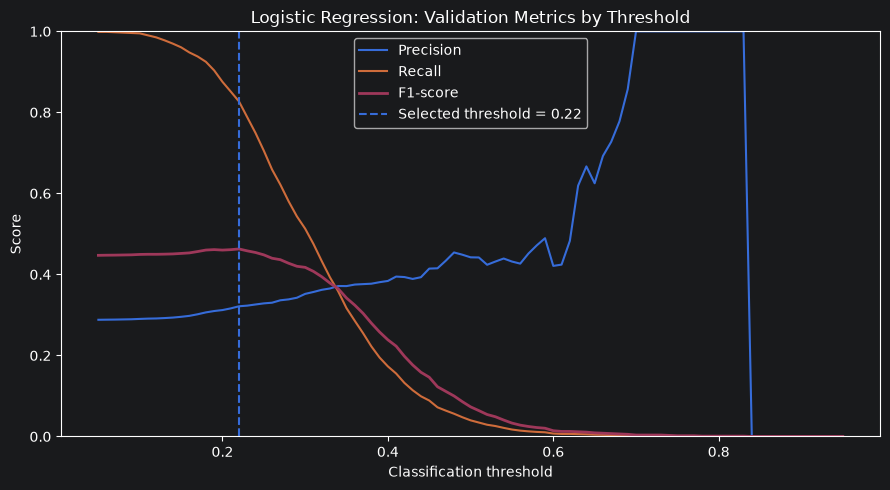

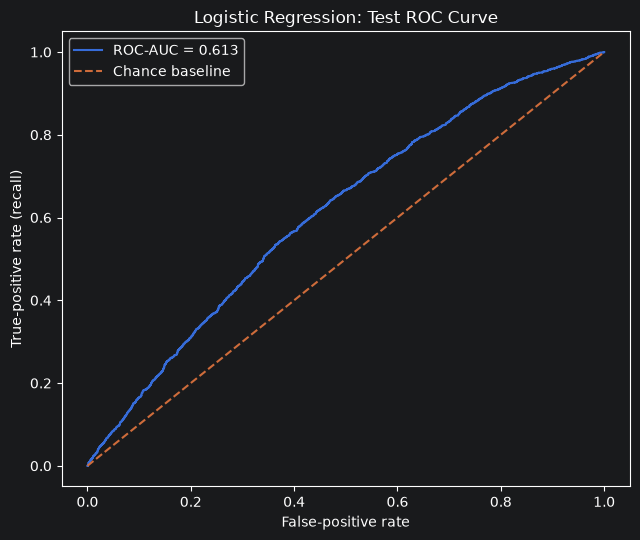

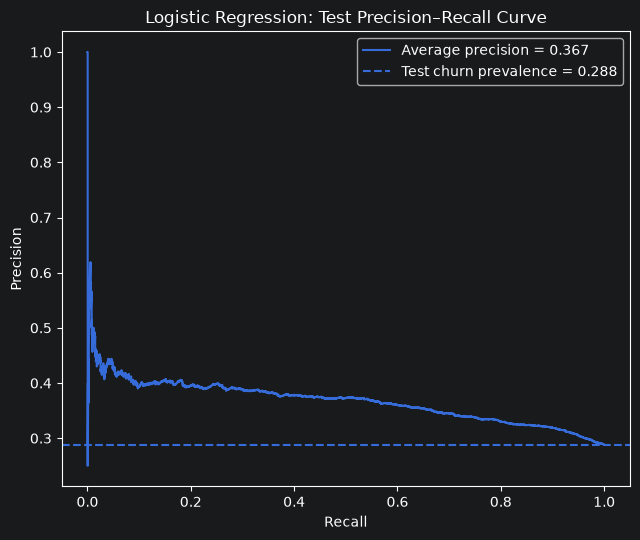

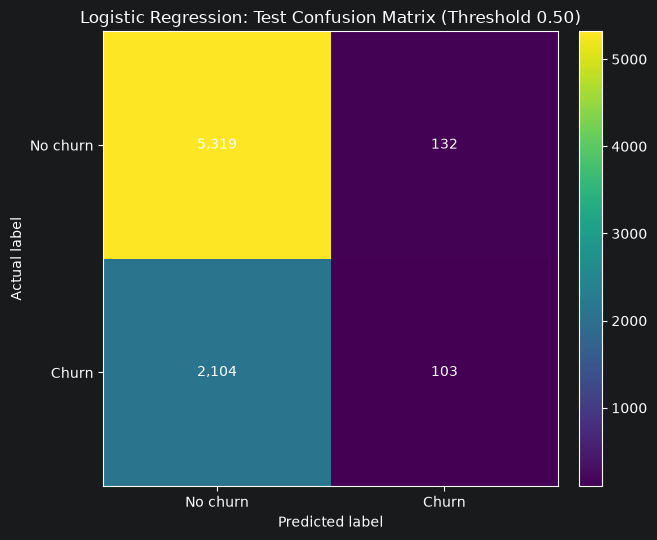

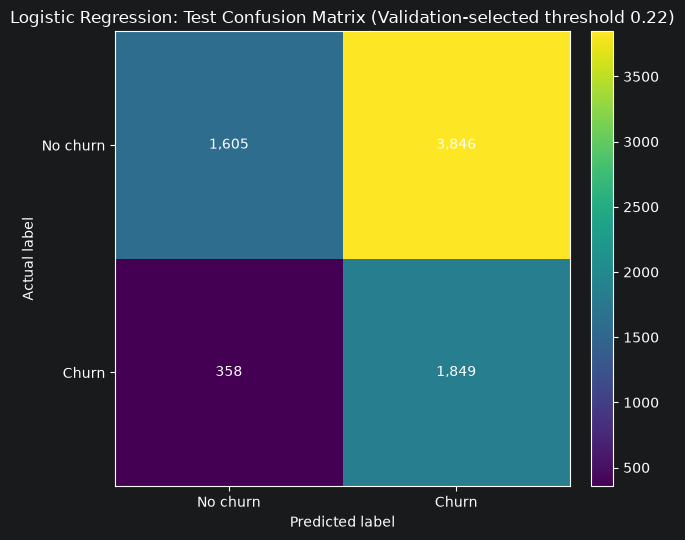


LOGISTIC REGRESSION VALIDATION-SELECTED THRESHOLD: 0.22
VALIDATION METRICS: {'threshold': 0.22, 'accuracy': 0.4469113229724435, 'precision': 0.3214159915463191, 'recall': 0.8269143633892161, 'f1_score': 0.4629042485732403, 'roc_auc': 0.5914368377514414, 'average_precision': 0.35722335132206645}
TEST METRICS AT 0.50: {'threshold': 0.5, 'accuracy': 0.708017759206059, 'precision': 0.43829787234042555, 'recall': 0.04666968735840508, 'f1_score': 0.08435708435708436, 'roc_auc': 0.6128186387153763, 'average_precision': 0.36741586500951723, 'confusion_matrix': [[5319, 132], [2104, 103]]}
TEST METRICS AT VALIDATION-SELECTED THRESHOLD: {'threshold': 0.22, 'accuracy': 0.4510316009401933, 'precision': 0.3246707638279192, 'recall': 0.8377888536474852, 'f1_score': 0.4679827891672994, 'roc_auc': 0.6128186387153763, 'average_precision': 0.36741586500951723, 'confusion_matrix': [[1605, 3846], [358, 1849]]}

Charts saved to: C:\Users\Kayode Ogunyemi\PycharmProjects\Ann_FinalProject\outputs\cell2cell_lo

In [19]:
from __future__ import annotations

import argparse
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
ID_COLUMNS = ["CustomerID"]
LEAKAGE_COLUMNS = [
    "RetentionCalls",
    "RetentionOffersAccepted",
    "MadeCallToRetentionTeam",
]


def calculate_metrics(y_true, probabilities, threshold):
    predicted = (probabilities >= threshold).astype(int)
    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(y_true, predicted)),
        "precision": float(precision_score(y_true, predicted, zero_division=0)),
        "recall": float(recall_score(y_true, predicted, zero_division=0)),
        "f1_score": float(f1_score(y_true, predicted, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, probabilities)),
        "average_precision": float(average_precision_score(y_true, probabilities)),
        "confusion_matrix": confusion_matrix(
            y_true, predicted, labels=[0, 1]
        ).tolist(),
    }


def save_plot(fig, plot_dir, filename):
    fig.tight_layout()
    fig.savefig(plot_dir / filename, dpi=160, bbox_inches="tight")
    plt.show(fig)
    plt.close(fig)


def main():
    parser = argparse.ArgumentParser(
        description="Train a Cell2Cell logistic regression benchmark and generate charts."
    )
    parser.add_argument("--data", default="cell2celltrain.csv")
    parser.add_argument(
        "--output-dir", default="outputs/cell2cell_logistic_benchmark"
    )
    # Supports notebook execution by ignoring IPython's injected arguments.
    args, _unknown = parser.parse_known_args()

    data_path = Path(args.data).expanduser()
    out = Path(args.output_dir).expanduser()
    plot_dir = out / "plots"
    out.mkdir(parents=True, exist_ok=True)
    plot_dir.mkdir(parents=True, exist_ok=True)

    if not data_path.exists():
        raise FileNotFoundError(f"Dataset not found: {data_path.resolve()}")

    df = pd.read_csv(data_path, low_memory=False)
    df.columns = df.columns.str.strip()
    if df.empty or "Churn" not in df.columns:
        raise ValueError("Dataset must be non-empty and contain a 'Churn' column.")

    rows_before = len(df)
    duplicate_count = int(df.duplicated().sum())
    df = df.drop_duplicates().copy()

    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].map(
            lambda value: value.strip() if isinstance(value, str) else value
        )
        df[col] = df[col].replace("", np.nan)

    target = df["Churn"].astype("string").str.strip().str.lower()
    y = target.map({"yes": 1, "no": 0, "1": 1, "0": 0})
    if y.isna().any() or y.nunique() != 2:
        raise ValueError("Churn must contain both classes, represented as Yes/No or 1/0.")
    y = y.astype("int64")

    excluded = [c for c in ID_COLUMNS + LEAKAGE_COLUMNS if c in df.columns]
    X = df.drop(columns=["Churn"] + excluded)

    # Same stratified split proportions and seed as the ANN experiments.
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, random_state=SEED, stratify=y
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
    )

    numeric = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
    categorical = [c for c in X_train.columns if c not in numeric]
    preprocessor = ColumnTransformer(
        [
            (
                "numeric",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                    ]
                ),
                numeric,
            ),
            (
                "categorical",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="most_frequent")),
                        (
                            "onehot",
                            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                        ),
                    ]
                ),
                categorical,
            ),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

    X_train_p = preprocessor.fit_transform(X_train)
    X_val_p = preprocessor.transform(X_val)
    X_test_p = preprocessor.transform(X_test)

    model = LogisticRegression(
        max_iter=2000,
        solver="lbfgs",
        class_weight=None,
        random_state=SEED,
    )
    model.fit(X_train_p, y_train)

    val_prob = model.predict_proba(X_val_p)[:, 1]
    test_prob = model.predict_proba(X_test_p)[:, 1]

    # Select the threshold on validation data only, maximizing F1.
    threshold_rows = []
    for threshold in np.round(np.arange(0.05, 0.951, 0.01), 2):
        result = calculate_metrics(y_val.to_numpy(), val_prob, float(threshold))
        result.pop("confusion_matrix")
        threshold_rows.append(result)
    validation_results = pd.DataFrame(threshold_rows)
    best = validation_results.sort_values(
        ["f1_score", "precision", "threshold"],
        ascending=[False, False, False],
    ).iloc[0]
    selected_threshold = float(best["threshold"])
    validation_results.to_csv(out / "validation_threshold_analysis.csv", index=False)

    test_050 = calculate_metrics(y_test.to_numpy(), test_prob, 0.50)
    test_selected = calculate_metrics(
        y_test.to_numpy(), test_prob, selected_threshold
    )

    # Threshold metric curves.
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(validation_results["threshold"], validation_results["precision"], label="Precision")
    ax.plot(validation_results["threshold"], validation_results["recall"], label="Recall")
    ax.plot(validation_results["threshold"], validation_results["f1_score"], label="F1-score", linewidth=2)
    ax.axvline(selected_threshold, linestyle="--", label=f"Selected threshold = {selected_threshold:.2f}")
    ax.set_title("Logistic Regression: Validation Metrics by Threshold")
    ax.set_xlabel("Classification threshold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.legend()
    save_plot(fig, plot_dir, "01_validation_threshold_metrics.png")

    # ROC and PR curves use test predictions for final evaluation.
    fpr, tpr, _ = roc_curve(y_test, test_prob)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.plot(fpr, tpr, label=f"ROC-AUC = {test_050['roc_auc']:.3f}")
    ax.plot([0, 1], [0, 1], linestyle="--", label="Chance baseline")
    ax.set_title("Logistic Regression: Test ROC Curve")
    ax.set_xlabel("False-positive rate")
    ax.set_ylabel("True-positive rate (recall)")
    ax.legend()
    save_plot(fig, plot_dir, "02_test_roc_curve.png")

    precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_prob)
    prevalence = float(np.mean(y_test))
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.plot(recall_curve, precision_curve, label=f"Average precision = {test_050['average_precision']:.3f}")
    ax.axhline(prevalence, linestyle="--", label=f"Test churn prevalence = {prevalence:.3f}")
    ax.set_title("Logistic Regression: Test Precision–Recall Curve")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend()
    save_plot(fig, plot_dir, "03_test_precision_recall_curve.png")

    # Confusion matrices at both thresholds.
    for suffix, result, label in [
        ("050", test_050, "Threshold 0.50"),
        ("selected", test_selected, f"Validation-selected threshold {selected_threshold:.2f}"),
    ]:
        cm = np.asarray(result["confusion_matrix"])
        fig, ax = plt.subplots(figsize=(6.5, 5.5))
        im = ax.imshow(cm, interpolation="nearest")
        ax.set_title(f"Logistic Regression: Test Confusion Matrix ({label})")
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("Actual label")
        ax.set_xticks([0, 1], ["No churn", "Churn"])
        ax.set_yticks([0, 1], ["No churn", "Churn"])
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        save_plot(fig, plot_dir, f"04_confusion_matrix_{suffix}.png")

    results = {
        "model": "LogisticRegression",
        "input_file": str(data_path.resolve()),
        "rows_before_duplicate_removal": int(rows_before),
        "duplicate_rows_removed": int(duplicate_count),
        "rows_after_duplicate_removal": int(len(df)),
        "split_rows": {
            "train": int(len(X_train)),
            "validation": int(len(X_val)),
            "test": int(len(X_test)),
        },
        "excluded_columns": excluded,
        "predictor_columns_before_encoding": int(X_train.shape[1]),
        "encoded_feature_count": int(X_train_p.shape[1]),
        "class_weight": None,
        "threshold_selection": (
            "Validation-only grid 0.05-0.95 in 0.01 increments; maximize F1; "
            "tie-break by precision, then higher threshold."
        ),
        "selected_threshold": selected_threshold,
        "validation_metrics_at_selected_threshold": {
            key: float(value) for key, value in best.to_dict().items()
        },
        "test_metrics_at_0.50": test_050,
        "test_metrics_at_validation_selected_threshold": test_selected,
        "test_churn_prevalence": prevalence,
    }

    joblib.dump(preprocessor, out / "preprocessor.joblib")
    joblib.dump(model, out / "logistic_regression.joblib")
    pd.DataFrame(
        {
            "actual_churn": y_test.to_numpy(),
            "churn_probability": test_prob,
            "predicted_at_050": (test_prob >= 0.50).astype(int),
            "predicted_at_validation_threshold": (
                test_prob >= selected_threshold
            ).astype(int),
        }
    ).to_csv(out / "test_predictions.csv", index=False)
    (out / "benchmark_results.json").write_text(
        json.dumps(results, indent=2), encoding="utf-8"
    )

    cm_050 = np.asarray(test_050["confusion_matrix"])
    cm_selected = np.asarray(test_selected["confusion_matrix"])
    report = [
        "CELL2CELL LOGISTIC REGRESSION BENCHMARK — INTERPRETATION",
        "=" * 61,
        "",
        f"Validation-selected threshold: {selected_threshold:.2f}.",
        "The threshold was selected using validation data only by maximizing F1-score.",
        "",
        "At test threshold 0.50:",
        (
            f"Accuracy={test_050['accuracy']:.4f}, precision={test_050['precision']:.4f}, "
            f"recall={test_050['recall']:.4f}, F1={test_050['f1_score']:.4f}, "
            f"ROC-AUC={test_050['roc_auc']:.4f}, average precision={test_050['average_precision']:.4f}."
        ),
        (
            f"Confusion matrix: TN={cm_050[0,0]}, FP={cm_050[0,1]}, "
            f"FN={cm_050[1,0]}, TP={cm_050[1,1]}."
        ),
        "",
        f"At validation-selected threshold {selected_threshold:.2f}:",
        (
            f"Accuracy={test_selected['accuracy']:.4f}, precision={test_selected['precision']:.4f}, "
            f"recall={test_selected['recall']:.4f}, F1={test_selected['f1_score']:.4f}, "
            f"ROC-AUC={test_selected['roc_auc']:.4f}, average precision={test_selected['average_precision']:.4f}."
        ),
        (
            f"Confusion matrix: TN={cm_selected[0,0]}, FP={cm_selected[0,1]}, "
            f"FN={cm_selected[1,0]}, TP={cm_selected[1,1]}."
        ),
        "",
        (
            "The ROC-AUC and average precision do not change between classification thresholds "
            "because threshold changes alter class labels, not probability ranking."
        ),
        (
            "Compare this benchmark with the ANN using the same test split and matching threshold "
            "policy. Do not claim either model is better until the real outputs are compared."
        ),
        "",
        f"Charts saved in: {plot_dir.resolve()}",
    ]
    (plot_dir / "chart_interpretation.txt").write_text("\n".join(report), encoding="utf-8")

    print("\nLOGISTIC REGRESSION VALIDATION-SELECTED THRESHOLD:", selected_threshold)
    print("VALIDATION METRICS:", results["validation_metrics_at_selected_threshold"])
    print("TEST METRICS AT 0.50:", test_050)
    print("TEST METRICS AT VALIDATION-SELECTED THRESHOLD:", test_selected)
    print(f"\nCharts saved to: {plot_dir.resolve()}")
    print(f"Interpretation saved to: {(plot_dir / 'chart_interpretation.txt').resolve()}")
    print(f"Artifacts saved to: {out.resolve()}")


if __name__ == "__main__":
    main()


**INTERPRETATION** - The ANN performs better across all six listed metrics at the respective selected thresholds, although the improvements are modest.
Both models have weak default-threshold churn detection. At 0.50, ANN recall is 5.26%, while logistic regression recall is 4.67%.
Threshold adjustment makes a substantial difference. The ANN identifies 1,889 of 2,207 actual churners; logistic regression identifies 1,849 of 2,207.
Neither model is a strong ranker yet. The ANN's ROC-AUC of 0.6314 and AP of 0.3872 suggest there is still considerable room to improve how effectively it separates churners from non-churners.